<a href="https://colab.research.google.com/github/vicayumi/Calculo_Numerico/blob/main/CN_interpola%C3%A7%C3%A3o_erros.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tarefa investigativa: erros em métodos de interpolação

### Aplicação: reconstrução da temperatura em uma barra aquecida

Uma barra homogênea de comprimento $L=6$ m está sujeita a temperaturas prescritas nas extremidades e recebe calor de uma fonte distribuída em seu interior. Sensores medem a temperatura em posições discretas. A equipe precisa estimar a temperatura em posições onde não há sensor e avaliar a incerteza dessas estimativas.

Esta atividade combina um modelo simplificado de transferência de calor com interpolação numérica. O objetivo não é resolver a equação diferencial de calor por diferenças finitas. O perfil analítico será usado como referência, para que os erros de diferentes métodos de interpolação possam ser medidos e comparados.

Você vai comparar **polinômio global de Lagrange** e uma **spline cúbica**, primeiro com dados exatos e depois com medições perturbadas por ruído.


## 1. Problema físico e equação de transferência de calor

### 1.1 Modelo físico

Considere uma barra sólida homogênea, com comprimento $L=6$ m e seção transversal constante. A temperatura varia principalmente ao longo do eixo $x$. As extremidades são mantidas a temperaturas conhecidas. No interior, uma fonte térmica volumétrica distribui energia ao longo da barra.

A equação geral de energia térmica, para propriedades constantes e sem mudança de fase, pode ser escrita como

$$\rho c_p\frac{\partial T}{\partial t}=k\nabla^2T+\dot q^{\prime\prime\prime}-\rho c_p\,\mathbf{u}\cdot\nabla T,$$

em que $T$ é a temperatura (K ou °C para diferenças), $t$ é o tempo (s), $\rho$ é a massa específica (kg m$^{-3}$), $c_p$ é o calor específico (J kg$^{-1}$ K$^{-1}$), $k$ é a condutividade térmica (W m$^{-1}$ K$^{-1}$), $\dot q^{\prime\prime\prime}$ é a geração volumétrica de calor (W m$^{-3}$) e $\mathbf{u}$ representa o movimento de um fluido, quando há advecção.

Para esta atividade, adotamos uma **barra sólida em regime estacionário**, sem escoamento interno, com condução unidimensional e geração de calor. Assim, $\partial T/\partial t=0$, $\mathbf{u}=0$ e $\nabla^2T=d^2T/dx^2$. A equação fica

$$k\frac{d^2T}{dx^2}+\dot q^{\prime\prime\prime}(x)=0,\qquad 0<x<L,$$

com condições de contorno de Dirichlet

$$T(0)=18\ ^\circ\mathrm C,\qquad T(L)=20.4\ ^\circ\mathrm C.$$

O primeiro termo representa a condução: diferenças espaciais de temperatura geram fluxo de calor. O termo $\dot q^{\prime\prime\prime}(x)$ representa energia adicionada por unidade de volume e de tempo. O sinal positivo de $\dot q^{\prime\prime\prime}$ indica geração interna de calor.

### 1.2 Perfil de referência usado no experimento

Para criar um caso com solução conhecida, definimos $\xi=x/L$ e adotamos

$$T(x)=18+2.4\,\xi+2.5\sin(\pi\xi),\qquad \xi=\frac{x}{L},\quad 0\le x\le L.$$

A parcela linear garante as temperaturas prescritas nas extremidades. A parcela senoidal representa um aquecimento distribuído mais intenso no interior e nulo nas bordas. Derivando duas vezes em relação à coordenada física $x$,

$$\frac{d^2T}{dx^2}=-\frac{2.5\pi^2}{L^2}\sin\left(\frac{\pi x}{L}\right).$$

Portanto, esse perfil satisfaz a equação estacionária se a geração volumétrica for

$$\dot q^{\prime\prime\prime}(x)=\frac{2.5\,k\pi^2}{L^2}\sin\left(\frac{\pi x}{L}\right).$$

Como $\sin(\pi x/L)\ge0$ dentro da barra, a fonte é não negativa. Não precisamos escolher um valor numérico para $k$: o objetivo é verificar a coerência do perfil e estudar a interpolação. A função analítica é uma referência idealizada; em uma aplicação experimental, seria preciso estimar propriedades, fontes, perdas e condições de contorno.

### 1.3 Questão investigativa

**Como a resposta depende da quantidade e posição dos sensores e do ruído de medição?**



A quantidade e a posição dos sensores determinam quanto da forma do perfil pode ser reconstruída. Com poucos sensores, há menos informação entre as medições e os erros tendem a crescer; acrescentar sensores geralmente melhora a aproximação deste perfil suave. A posição também importa: nós equiespaçados podem produzir oscilações no polinômio global, principalmente junto às extremidades, enquanto nós de Chebyshev-Lobatto concentram medições nas bordas e costumam reduzir esse efeito. Splines usam informação local e tendem a ser mais estáveis quando se aumenta o número de sensores.

O ruído altera a conclusão: interpoladores exatos passam por cada leitura, inclusive pelo erro de medição, e podem oscilar. Portanto, com leituras ruidosas, deve-se quantificar a incerteza e preferir um ajuste suavizado (ou outra regressão) em vez de forçar a curva a passar por todos os pontos. O efeito depende da intensidade e da distribuição do ruído, da posição dos sensores e do método; mais sensores ajudam a revelar a forma global, mas não eliminam ruído nem garantem melhora se as medições forem mal posicionadas.

### O que significa erro de interpolação?

Em um ponto de avaliação $x$, o erro assinado é $e(x)=p(x)-T(x)$. O erro absoluto é $|e(x)|$. Como a interpolação reproduz os nós, o erro nesses pontos pode ser praticamente zero; por isso, avaliaremos também muitos pontos **entre** os nós.

Usaremos: erro máximo absoluto $E_{max}=\max_j|e_j|$; erro médio absoluto (MAE) $=\frac{1}{m}\sum_j|e_j|$; raiz do erro quadrático médio (RMSE) $=\sqrt{\frac{1}{m}\sum_j e_j^2}$. O RMSE penaliza mais erros grandes.

## 2. Figura do problema e preparação do ambiente

A figura esquematiza a barra, os sensores, as temperaturas nas extremidades e a fonte térmica interna. A curva corresponde ao perfil de referência usado no experimento. Os pontos são as posições onde os sensores amostram a temperatura.

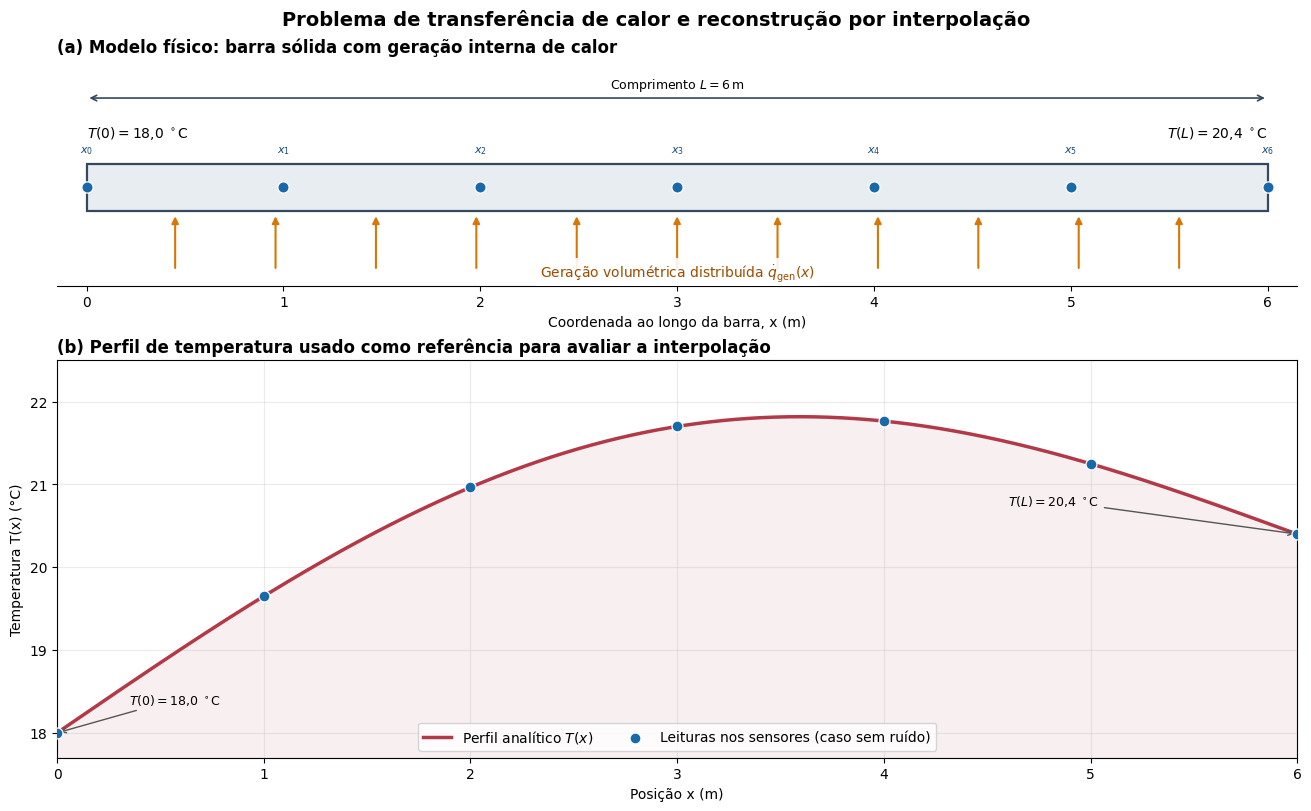

Temperaturas nas extremidades: T(0)=18.0 °C e T(L)=20.4 °C


In [1]:
# Preparação do modelo e bibliotecas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import BarycentricInterpolator, interp1d, CubicSpline
from matplotlib.patches import Rectangle

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (9, 5)
L = 6.0  # comprimento da barra, m

def temperatura_real(x):
    """Perfil analítico de referência em °C; x é dado em metros."""
    x = np.asarray(x, dtype=float)
    xi = x/L
    return 18 + 2.4*xi + 2.5*np.sin(np.pi*xi)

x_min, x_max = 0.0, L
x_fino = np.linspace(x_min, x_max, 2001)
T_fino = temperatura_real(x_fino)

# Figura do problema: esquema físico e perfil analítico em painéis separados

x_sensores_fig = np.linspace(0, L, 7)
T_sensores_fig = temperatura_real(x_sensores_fig)

fig = plt.figure(figsize=(13, 8), constrained_layout=True)
gs = fig.add_gridspec(2, 1, height_ratios=[0.85, 1.5])
ax_esq = fig.add_subplot(gs[0])
ax_perfil = fig.add_subplot(gs[1])

# Painel (a): barra física, sensores e fonte interna distribuída
ax_esq.set_title("(a) Modelo físico: barra sólida com geração interna de calor", loc="left", fontsize=12, weight="bold")
barra_y, barra_h = 0.40, 0.25
ax_esq.add_patch(Rectangle((0, barra_y), L, barra_h, facecolor="#e8edf2",
                           edgecolor="#34495e", linewidth=1.6, zorder=1))
# Sensores ao longo do eixo da barra
ax_esq.scatter(x_sensores_fig, np.full_like(x_sensores_fig, barra_y+barra_h/2),
               s=65, marker="o", facecolor="#1769aa", edgecolor="white", linewidth=0.9,
               zorder=4, label="Sensores")
# Aquecimento interno: setas iguais identificam geração distribuída, sem sugerir fluxo de calor externo
for xpos in np.linspace(0.45, 5.55, 11):
    ax_esq.annotate("", xy=(xpos, barra_y-0.015), xytext=(xpos, 0.08),
                    arrowprops={"arrowstyle":"-|>", "color":"#d97706", "lw":1.5}, zorder=3)
ax_esq.text(L/2, 0.015, r"Geração volumétrica distribuída $\dot{q}_{\mathrm{gen}}(x)$",
            ha="center", va="bottom", color="#9a4d00", fontsize=10,
            bbox={"facecolor":"white", "edgecolor":"none", "alpha":0.88, "pad":2.5})
ax_esq.text(0, 0.77, r"$T(0)=18{,}0\ ^\circ\mathrm{C}$", ha="left", va="bottom", fontsize=10)
ax_esq.text(L, 0.77, r"$T(L)=20{,}4\ ^\circ\mathrm{C}$", ha="right", va="bottom", fontsize=10)
# Linha de dimensão e eixo longitudinal
ax_esq.annotate("", xy=(L, 1.00), xytext=(0, 1.00),
                arrowprops={"arrowstyle":"<->", "color":"#34495e", "lw":1.2})
ax_esq.text(L/2, 1.025, r"Comprimento $L=6\,\mathrm{m}$", ha="center", va="bottom", fontsize=9)
for i, xpos in enumerate(x_sensores_fig):
    ax_esq.text(xpos, barra_y+barra_h+0.04, rf"$x_{i}$", ha="center", va="bottom", fontsize=8, color="#174a73")
ax_esq.set_xlim(-0.15, L+0.15); ax_esq.set_ylim(0, 1.2)
ax_esq.set_xlabel("Coordenada ao longo da barra, x (m)")
ax_esq.set_yticks([]); ax_esq.grid(False)
for spine in ["left", "right", "top"]: ax_esq.spines[spine].set_visible(False)

# Painel (b): curva de referência e posições amostradas
ax_perfil.set_title("(b) Perfil de temperatura usado como referência para avaliar a interpolação",
                    loc="left", fontsize=12, weight="bold")
ax_perfil.plot(x_fino, T_fino, color="#b23a48", linewidth=2.5,
               label=r"Perfil analítico $T(x)$", zorder=2)
ax_perfil.scatter(x_sensores_fig, T_sensores_fig, s=62, marker="o",
                  facecolor="#1769aa", edgecolor="white", linewidth=0.9,
                  label="Leituras nos sensores (caso sem ruído)", zorder=4)
ax_perfil.fill_between(x_fino, T_fino, np.min(T_fino)-0.3,
                       color="#b23a48", alpha=0.08, zorder=1)
ax_perfil.annotate(r"$T(0)=18{,}0\ ^\circ\mathrm{C}$",
                   xy=(0, temperatura_real(0)), xytext=(0.35, 18.35),
                   arrowprops={"arrowstyle":"->", "color":"#555"}, fontsize=9)
ax_perfil.annotate(r"$T(L)=20{,}4\ ^\circ\mathrm{C}$",
                   xy=(L, temperatura_real(L)), xytext=(4.6, 20.75),
                   arrowprops={"arrowstyle":"->", "color":"#555"}, fontsize=9)
ax_perfil.set_xlim(0, L); ax_perfil.set_ylim(17.7, 22.5)
ax_perfil.set_xlabel("Posição x (m)")
ax_perfil.set_ylabel("Temperatura T(x) (°C)")
ax_perfil.grid(True, alpha=0.25); ax_perfil.legend(loc="lower center", ncol=2, frameon=True)
fig.suptitle("Problema de transferência de calor e reconstrução por interpolação", fontsize=14, weight="bold")
plt.show()

print(f"Temperaturas nas extremidades: T(0)={temperatura_real(0):.1f} °C e T(L)={temperatura_real(L):.1f} °C")

Spline quadrática

In [2]:
def spline_quadratica_coef(x, y):
    """Spline quadrática C1 com condição c_0=0; retorna a,b,c locais."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    n = len(x)-1
    if n < 1 or len(y) != len(x) or np.any(np.diff(x) <= 0):
        raise ValueError("x deve ser crescente e ter o mesmo tamanho de y.")
    A = np.zeros((3*n, 3*n)); rhs = np.zeros(3*n); row = 0
    # S_i(x_i)=y_i
    for i in range(n):
        A[row, i] = 1; rhs[row] = y[i]; row += 1
    # S_i(x_(i+1))=y_(i+1)
    for i in range(n):
        h = x[i+1]-x[i]
        A[row, i] = 1; A[row, n+i] = h; A[row, 2*n+i] = h*h
        rhs[row] = y[i+1]; row += 1
    # Continuidade da primeira derivada nos nós internos
    for i in range(n-1):
        h = x[i+1]-x[i]
        A[row, n+i] = 1; A[row, 2*n+i] = 2*h; A[row, n+i+1] = -1
        row += 1
    # Condição de contorno: c_0=0
    A[row, 2*n] = 1
    coef = np.linalg.solve(A, rhs)
    return coef[:n], coef[n:2*n], coef[2*n:]

def spline_quadratica_avalia(x, coef, xq):
    a, b, c = coef
    xq = np.asarray(xq, dtype=float)
    idx = np.clip(np.searchsorted(x, xq, side="right")-1, 0, len(a)-1)
    t = xq-x[idx]
    return a[idx] + b[idx]*t + c[idx]*t**2

def criar_metodos(x, y):
    """Retorna dicionário: interpoladores callable para quatro métodos."""
    lagrange = BarycentricInterpolator(x, y)
    linear = interp1d(x, y, kind="linear", bounds_error=True)
    quad_coef = spline_quadratica_coef(x, y)
    quad = lambda z: spline_quadratica_avalia(x, quad_coef, z)
    cubica = CubicSpline(x, y, bc_type="natural")
    return {"Lagrange global": lagrange,
            "Spline linear": linear,
            "Spline quadrática": quad,
            "Spline cúbica natural": cubica}

def calcular_metricas(metodos, x_teste, y_verdadeiro):
    linhas = []
    for nome, metodo in metodos.items():
        erro = np.asarray(metodo(x_teste))-np.asarray(y_verdadeiro)
        linhas.append({"Método": nome,
                       "Erro máximo (°C)": np.max(np.abs(erro)),
                       "MAE (°C)": np.mean(np.abs(erro)),
                       "RMSE (°C)": np.sqrt(np.mean(erro**2))})
    return pd.DataFrame(linhas).sort_values("RMSE (°C)").reset_index(drop=True)

print("Funções de interpolação e métricas definidas.")

Funções de interpolação e métricas definidas.


## 3. Métodos de interpolação e métricas de erro

O interpolador global de Lagrange passa por todos os sensores usando um único polinômio. Usamos a forma baricêntrica, que evita expandir diretamente os coeficientes e costuma ser numericamente mais estável.

As splines constroem polinômios por intervalos. A spline linear conecta pontos por retas. A quadrática deste notebook impõe continuidade da função e da primeira derivada e usa a condição de contorno $c_0=0$ no primeiro intervalo. A spline cúbica natural impõe continuidade até a segunda derivada e segunda derivada nula nas extremidades.

Para quantificar a diferença, calculamos $e(x)=T_{interp}(x)-T_{ref}(x)$. O erro máximo mostra o pior desvio na malha. O MAE dá o desvio absoluto médio. O RMSE penaliza mais os erros de grande magnitude. Todos têm unidade de graus Celsius.

A malha fina serve como conjunto de pontos de avaliação: os valores nela não são novos sensores. Assim, a comparação mede desempenho entre os nós.

In [3]:
def spline_quadratica_coef(x, y):
    """Spline quadrática C1 com condição c_0=0; retorna a,b,c locais."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    n = len(x)-1
    if n < 1 or len(y) != len(x) or np.any(np.diff(x) <= 0):
        raise ValueError("x deve ser crescente e ter o mesmo tamanho de y.")
    A = np.zeros((3*n, 3*n)); rhs = np.zeros(3*n); row = 0
    # S_i(x_i)=y_i
    for i in range(n):
        A[row, i] = 1; rhs[row] = y[i]; row += 1
    # S_i(x_(i+1))=y_(i+1)
    for i in range(n):
        h = x[i+1]-x[i]
        A[row, i] = 1; A[row, n+i] = h; A[row, 2*n+i] = h*h
        rhs[row] = y[i+1]; row += 1
    # Continuidade da primeira derivada nos nós internos
    for i in range(n-1):
        h = x[i+1]-x[i]
        A[row, n+i] = 1; A[row, 2*n+i] = 2*h; A[row, n+i+1] = -1
        row += 1
    # Condição de contorno: c_0=0
    A[row, 2*n] = 1
    coef = np.linalg.solve(A, rhs)
    return coef[:n], coef[n:2*n], coef[2*n:]

def spline_quadratica_avalia(x, coef, xq):
    a, b, c = coef
    xq = np.asarray(xq, dtype=float)
    idx = np.clip(np.searchsorted(x, xq, side="right")-1, 0, len(a)-1)
    t = xq-x[idx]
    return a[idx] + b[idx]*t + c[idx]*t**2

def criar_metodos(x, y):
    """Retorna dicionário: interpoladores callable para quatro métodos."""
    lagrange = BarycentricInterpolator(x, y)
    linear = interp1d(x, y, kind="linear", bounds_error=True)
    quad_coef = spline_quadratica_coef(x, y)
    quad = lambda z: spline_quadratica_avalia(x, quad_coef, z)
    cubica = CubicSpline(x, y, bc_type="natural")
    return {"Lagrange global": lagrange,
            "Spline linear": linear,
            "Spline quadrática": quad,
            "Spline cúbica natural": cubica}

def calcular_metricas(metodos, x_teste, y_verdadeiro):
    linhas = []
    for nome, metodo in metodos.items():
        erro = np.asarray(metodo(x_teste))-np.asarray(y_verdadeiro)
        linhas.append({"Método": nome,
                       "Erro máximo (°C)": np.max(np.abs(erro)),
                       "MAE (°C)": np.mean(np.abs(erro)),
                       "RMSE (°C)": np.sqrt(np.mean(erro**2))})
    return pd.DataFrame(linhas).sort_values("RMSE (°C)").reset_index(drop=True)

print("Funções de interpolação e métricas definidas.")

Funções de interpolação e métricas definidas.


## Etapa 1 — Interpolação com dados exatos
Suponha primeiro que os sensores sejam perfeitos. Coloque sete sensores em posições igualmente espaçadas, incluindo as duas extremidades. Os valores registrados são então exatamente $T(x_i)$.

### Passo a passo
1. Construa o vetor das posições e avalie o perfil de referência nesses pontos.
2. Crie a interpolação com `criar_metodos`.
3. Avalie cada método em `x_fino`, uma malha densa entre 0 e 6 m.
4. Calcule $E_{max}$, MAE e RMSE comparando cada curva com `T_fino`.
5. Faça um gráfico das temperaturas e outro dos erros assinados.




,Método,Erro máximo (°C),MAE (°C),RMSE (°C)
0,Lagrange global,0.000085,0.000019,0.000033
1,Spline cúbica natural,0.000506,0.000184,0.000239
2,Spline quadrática,0.023927,0.014950,0.016466
3,Spline linear,0.082294,0.036510,0.043967


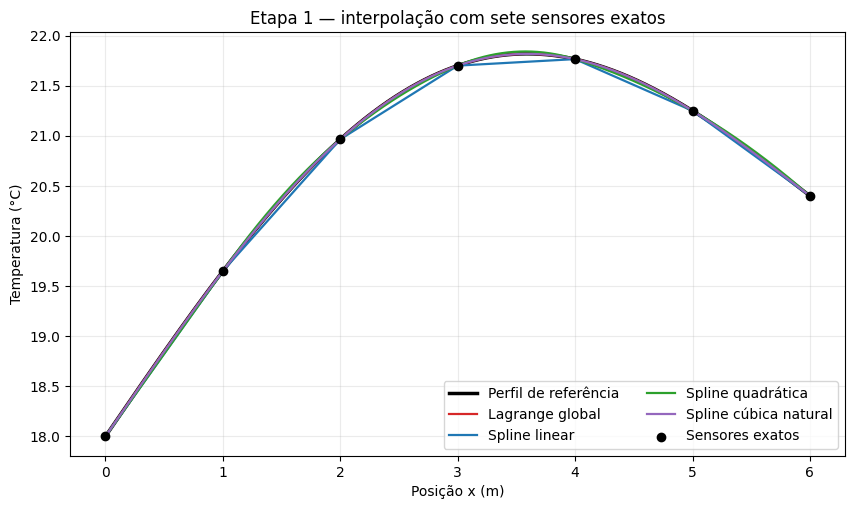

In [4]:
x_nos_7 = np.linspace(x_min, x_max, 7)
y_nos_7 = temperatura_real(x_nos_7)
metodos_7 = criar_metodos(x_nos_7, y_nos_7)

# TODO: calcular a tabela de métricas na malha fina
# metricas_7 = calcular_metricas(metodos_7, x_fino, T_fino)
# display(metricas_7)

# TODO: sobreponha os quatro métodos à função verdadeira e marque os nós
metricas_7 = calcular_metricas(metodos_7, x_fino, T_fino)
display(metricas_7.round(6))

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(x_fino, T_fino, color='black', lw=2.5, label='Perfil de referência')
cores = {'Lagrange global':'#d62728', 'Spline linear':'#1f77b4',
         'Spline quadrática':'#2ca02c', 'Spline cúbica natural':'#9467bd'}
for nome, metodo in metodos_7.items():
    ax.plot(x_fino, metodo(x_fino), lw=1.6, color=cores[nome], label=nome)
ax.scatter(x_nos_7, y_nos_7, color='black', s=36, zorder=5, label='Sensores exatos')
ax.set(xlabel='Posição x (m)', ylabel='Temperatura (°C)', title='Etapa 1 — interpolação com sete sensores exatos')
ax.grid(alpha=.25); ax.legend(ncol=2); plt.show()


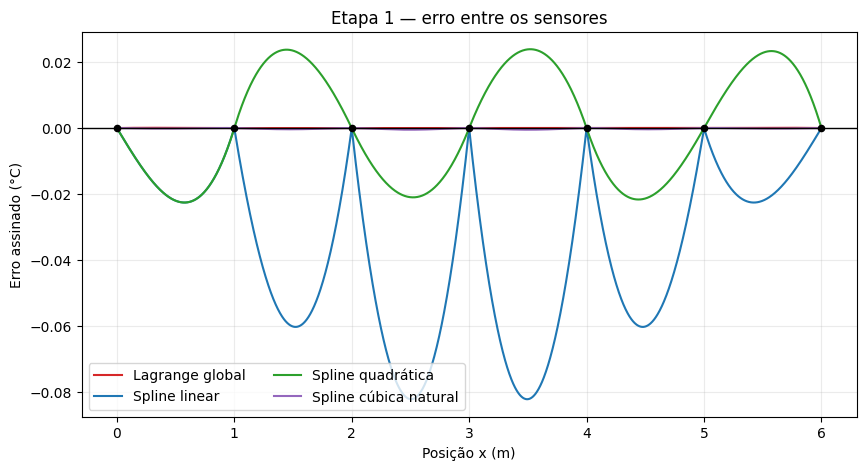

In [5]:
# TODO: gráfico dos erros assinados método a método.
# Dica: erro = metodo(x_fino) - T_fino

fig, ax = plt.subplots(figsize=(10, 5))
for nome, metodo in metodos_7.items():
    ax.plot(x_fino, np.asarray(metodo(x_fino))-T_fino, lw=1.5, color=cores[nome], label=nome)
ax.axhline(0, color='black', lw=1)
ax.scatter(x_nos_7, np.zeros_like(x_nos_7), color='black', s=20, zorder=4)
ax.set(xlabel='Posição x (m)', ylabel='Erro assinado (°C)', title='Etapa 1 — erro entre os sensores')
ax.grid(alpha=.25); ax.legend(ncol=2); plt.show()


## Etapa 2 — Número e posição dos sensores

Nesta etapa, investigue somente o polinômio global de Lagrange. A interpolação polinomial global pode oscilar entre nós, sobretudo perto das extremidades, quando se usam muitos nós equiespaçados. A distribuição de Chebyshev concentra nós nas bordas e pode reduzir esse efeito.

Para $N$ nós de Chebyshev-Lobatto em $[a,b]$, use

$$x_k=\frac{a+b}{2}+\frac{b-a}{2}\cos\left(\frac{k\pi}{N-1}\right),\quad k=0,\ldots,N-1.$$

Ordene as posições crescentemente. Compare $N=5,9,13,17$ para nós equiespaçados e de Chebyshev. Para cada caso, avalie o erro em todos os pontos da malha fina e registre o erro máximo e o RMSE.

**Atenção:** uma redução de erro neste perfil particular não prova que o mesmo ocorrerá para qualquer função. Relacione a observação à suavidade e à estrutura do perfil usado.

,N,Distribuição,Erro máximo (°C),RMSE (°C)
0,5,Equiespaçados,4.530260e-03,2.159570e-03
1,5,Chebyshev-Lobatto,2.326600e-03,1.532700e-03
2,9,Equiespaçados,1.040000e-06,3.400000e-07
3,9,Chebyshev-Lobatto,2.200000e-07,1.200000e-07
4,13,Equiespaçados,0.000000e+00,0.000000e+00
5,13,Chebyshev-Lobatto,0.000000e+00,0.000000e+00
6,17,Equiespaçados,0.000000e+00,0.000000e+00
7,17,Chebyshev-Lobatto,0.000000e+00,0.000000e+00


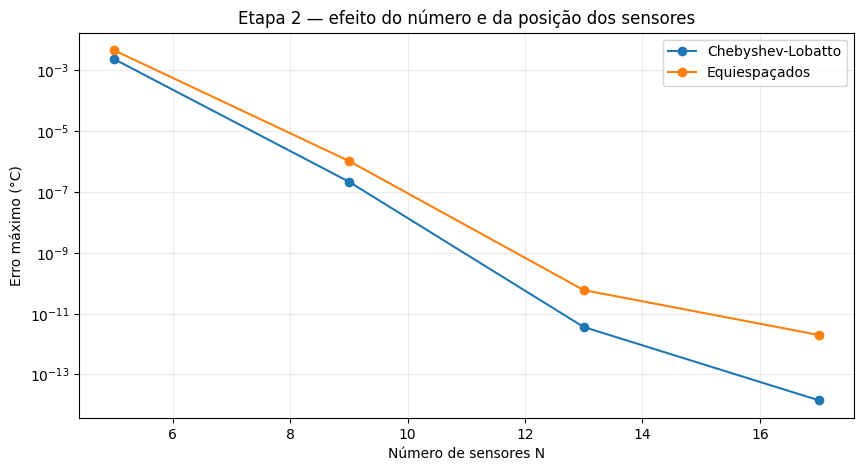

In [6]:
def nos_chebyshev_lobatto(a, b, N):
    k = np.arange(N)
    z = np.cos(k*np.pi/(N-1))
    return np.sort((a+b)/2 + (b-a)*z/2)

# TODO: compare N = 5, 9, 13 e 17
# Para cada N, construa Lagrange com nós equiespaçados e com nós de Chebyshev.
# Calcule Emax e RMSE usando x_fino e T_fino.
# Organize os resultados em um DataFrame.

# tabela_nos = ...
# display(tabela_nos)
linhas_nos = []
for N in (5, 9, 13, 17):
    for distribuicao, nos in [('Equiespaçados', np.linspace(x_min, x_max, N)),
                              ('Chebyshev-Lobatto', nos_chebyshev_lobatto(x_min, x_max, N))]:
        pol = BarycentricInterpolator(nos, temperatura_real(nos))
        erro = np.asarray(pol(x_fino))-T_fino
        linhas_nos.append({'N': N, 'Distribuição': distribuicao,
                           'Erro máximo (°C)': np.max(np.abs(erro)),
                           'RMSE (°C)': np.sqrt(np.mean(erro**2))})
tabela_nos = pd.DataFrame(linhas_nos)
display(tabela_nos.round(8))

fig, ax = plt.subplots(figsize=(10, 5))
for dist, grupo in tabela_nos.groupby('Distribuição'):
    ax.plot(grupo['N'], grupo['Erro máximo (°C)'], marker='o', label=dist)
ax.set_yscale('log'); ax.set(xlabel='Número de sensores N', ylabel='Erro máximo (°C)',
    title='Etapa 2 — efeito do número e da posição dos sensores')
ax.grid(True, which='both', alpha=.25); ax.legend(); plt.show()


,N,Método,Erro máximo (°C),RMSE (°C),Construção (ms),Avaliação (ms)
0,4,Lagrange equiespaçado,0.109039,0.068296,0.295913,0.401405
1,4,Lagrange Chebyshev,0.142977,0.080945,0.223059,0.327991
2,4,Spline cúbica natural,0.010177,0.004787,0.504683,0.111660
3,5,Lagrange equiespaçado,0.004530,0.002160,0.229855,0.332044
4,5,Lagrange Chebyshev,0.002327,0.001533,0.193706,0.342610
5,5,Spline cúbica natural,0.002665,0.001333,0.450096,0.106601
6,6,Lagrange equiespaçado,0.003282,0.001512,0.224948,0.346334
7,6,Lagrange Chebyshev,0.003017,0.001725,0.204055,0.362498
8,6,Spline cúbica natural,0.001118,0.000513,0.421080,0.102410


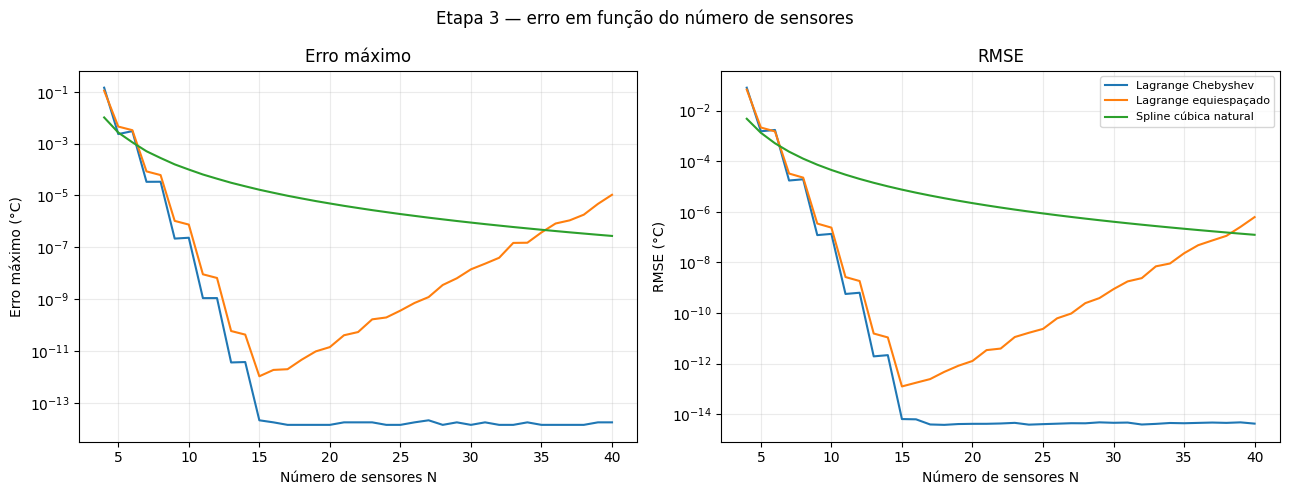

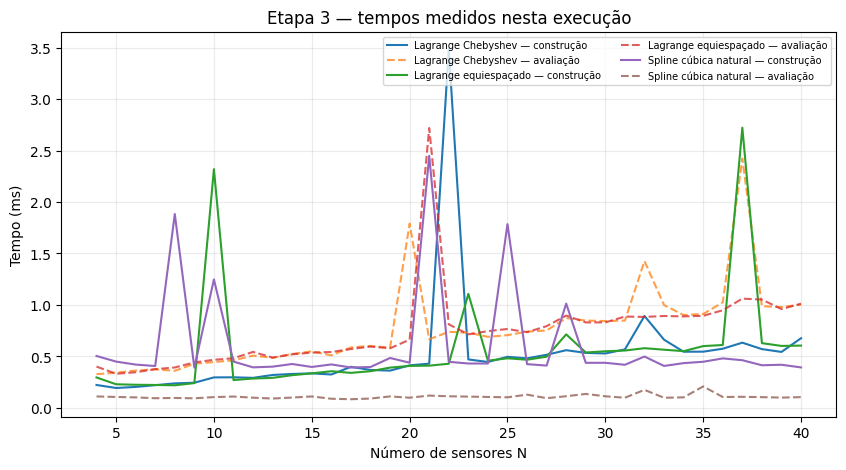

,N,Método,Erro máximo (°C),RMSE (°C)
0,18,Lagrange Chebyshev,0.000000e+00,0.000000e+00
1,15,Lagrange equiespaçado,0.000000e+00,0.000000e+00
2,40,Spline cúbica natural,2.700000e-07,1.200000e-07


In [7]:
from time import perf_counter

Ns_estudo = np.arange(4, 41)
linhas_estudo = []
for N in Ns_estudo:
    configuracoes = [
        ('Lagrange equiespaçado', np.linspace(x_min, x_max, N), 'lagrange'),
        ('Lagrange Chebyshev', nos_chebyshev_lobatto(x_min, x_max, N), 'lagrange'),
        ('Spline cúbica natural', np.linspace(x_min, x_max, N), 'spline')]
    for metodo_nome, nos, tipo in configuracoes:
        valores = temperatura_real(nos)
        t0 = perf_counter()
        interpolador = (BarycentricInterpolator(nos, valores) if tipo == 'lagrange'
                        else CubicSpline(nos, valores, bc_type='natural'))
        tempo_construcao = perf_counter()-t0
        t0 = perf_counter()
        estimativa = np.asarray(interpolador(x_fino))
        tempo_avaliacao = perf_counter()-t0
        erro = estimativa-T_fino
        linhas_estudo.append({'N': N, 'Método': metodo_nome,
            'Erro máximo (°C)': np.max(np.abs(erro)),
            'RMSE (°C)': np.sqrt(np.mean(erro**2)),
            'Construção (ms)': 1000*tempo_construcao,
            'Avaliação (ms)': 1000*tempo_avaliacao})

tabela_estudo = pd.DataFrame(linhas_estudo)
display(tabela_estudo.head(9).round(6))
fig, eixos = plt.subplots(1, 2, figsize=(13, 5))
for metodo_nome, grupo in tabela_estudo.groupby('Método'):
    eixos[0].plot(grupo.N, grupo['Erro máximo (°C)'].clip(lower=1e-16), label=metodo_nome)
    eixos[1].plot(grupo.N, grupo['RMSE (°C)'].clip(lower=1e-16), label=metodo_nome)
for ax, titulo, eixo_y in [(eixos[0], 'Erro máximo', 'Erro máximo (°C)'),
                           (eixos[1], 'RMSE', 'RMSE (°C)')]:
    ax.set_yscale('log'); ax.set_xlabel('Número de sensores N'); ax.set_ylabel(eixo_y)
    ax.set_title(titulo); ax.grid(True, which='both', alpha=.25)
eixos[1].legend(fontsize=8); fig.suptitle('Etapa 3 — erro em função do número de sensores')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
for metodo_nome, grupo in tabela_estudo.groupby('Método'):
    ax.plot(grupo.N, grupo['Construção (ms)'], label=f'{metodo_nome} — construção')
    ax.plot(grupo.N, grupo['Avaliação (ms)'], linestyle='--', alpha=.75,
            label=f'{metodo_nome} — avaliação')
ax.set(xlabel='Número de sensores N', ylabel='Tempo (ms)',
       title='Etapa 3 — tempos medidos nesta execução')
ax.grid(alpha=.25); ax.legend(fontsize=7, ncol=2); plt.show()

resumo_estudo = (tabela_estudo.loc[tabela_estudo.groupby('Método')['RMSE (°C)'].idxmin(),
                  ['N','Método','Erro máximo (°C)','RMSE (°C)']]
                 .sort_values('Método').reset_index(drop=True))
display(resumo_estudo.round(8))


## Etapa 3 — Estudo de caso e decisão técnica

Faça $N$ variar de 4 a 40. Compare erro máximo e RMSE em escala logarítmica para Lagrange equiespaçado, Lagrange com Chebyshev e spline cúbica natural. Registre o tempo de construção e de avaliação. Discuta o custo e a estabilidade numérica. Para o perfil suave escolhido, haverá necessariamente um único método superior para todo $N$?

**Etapa 3)** O código compara os três métodos para cada $N=4,\ldots,40$, mede separadamente a construção e a avaliação, e plota os erros máximo e RMSE em escala logarítmica. Os tempos dependem do computador, da versão das bibliotecas e da carga do ambiente; por isso, devem ser lidos como medições desta execução, não como constantes universais.

Não há garantia de um único método superior para todo $N$. Para este perfil, que é suave e analítico, nós de Chebyshev tendem a controlar melhor as oscilações do polinômio global do que nós equiespaçados quando $N$ cresce. A spline cúbica natural usa informação local, tem custo de construção aproximadamente linear no número de nós e evita o crescimento de grau global; o polinômio global pode ter baixo erro para alguns valores de $N$, mas fica mais sensível à distribuição dos nós e ao arredondamento. A tabela e as curvas geradas são a evidência quantitativa específica deste perfil. Valores de erro próximos da precisão de máquina não devem ser interpretados como melhora física significativa.

## Etapa 4 — Estudo de caso e decisão técnica

Uma equipe precisa estimar a temperatura em posições internas da barra, com sensores ruidosos. Não haverá sensores em todos os pontos e a solução verdadeira será desconhecida em campo. Com base nos experimentos, escreva uma recomendação técnica.

A recomendação deve responder:
- que método escolheria com poucos sensores exatos e por quê;
- como a recomendação muda quando se aumenta o número de sensores;
- o que faria quando os sensores apresentam ruído;
- que cuidados adotaria perto das extremidades;
- que limitações permanecem quando a temperatura verdadeira não é conhecida.

Use pelo menos duas métricas da atividade. Diferencie interpolação dentro do intervalo medido de extrapolação além dele.

,Método,Erro máximo (°C),MAE (°C),RMSE (°C)
0,Spline suavizada,0.230921,0.106588,0.126754
1,Spline linear,0.379265,0.136685,0.167713
2,Spline cúbica natural,0.382519,0.149095,0.187698
3,Lagrange global,0.765881,0.304279,0.361544
4,Spline quadrática,0.907597,0.301895,0.399418


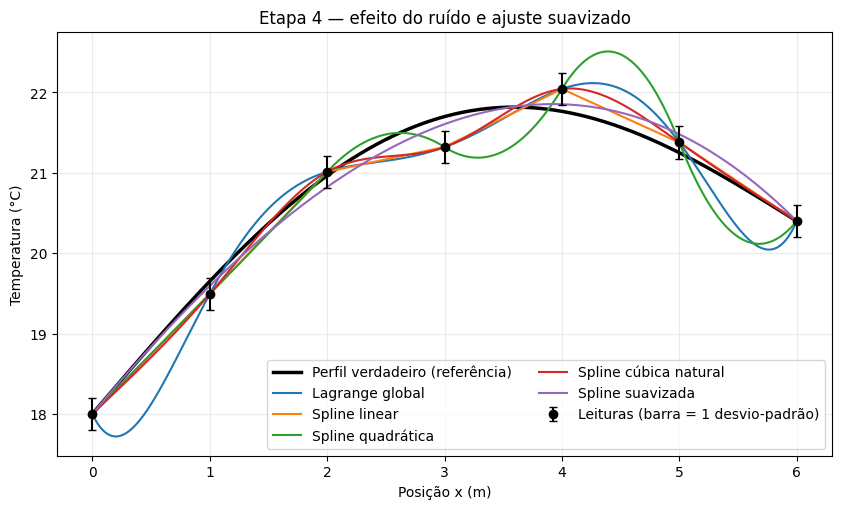

Ruído simulado: sigma = 0.20 °C; réplicas = 500; semente = 2026.
Média (desvio-padrão entre réplicas) das métricas do ajuste suavizado:
Emax = 0.2374 (0.0818) °C
MAE  = 0.1119 (0.0437) °C
RMSE = 0.1346 (0.0497) °C


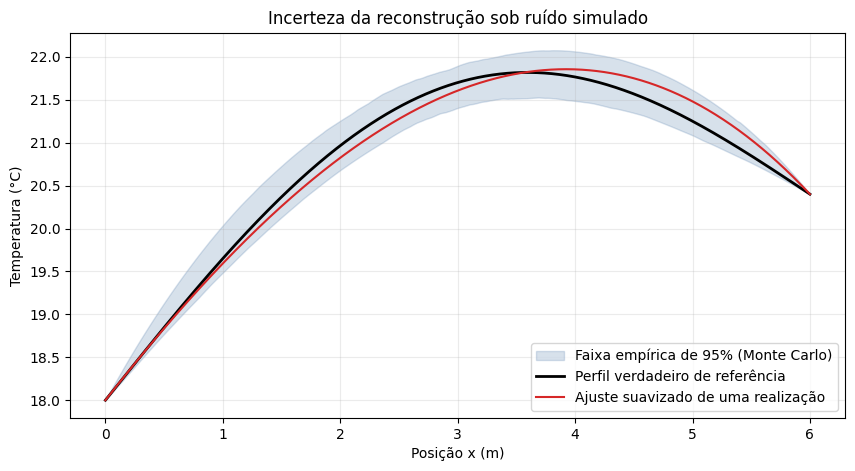

In [8]:
from scipy.interpolate import UnivariateSpline

rng = np.random.default_rng(2026)
sigma_ruido = 0.20  # desvio-padrão do ruído, em °C
x_ruidosos = np.linspace(x_min, x_max, 7)
y_exatos = temperatura_real(x_ruidosos)
y_medidos = y_exatos.copy()
mascara_interior = (x_ruidosos > x_min) & (x_ruidosos < x_max)
y_medidos[mascara_interior] += rng.normal(0, sigma_ruido, mascara_interior.sum())

metodos_ruidosos = criar_metodos(x_ruidosos, y_medidos)
# Ajuste suavizado: s aproximadamente igual a n*sigma^2 quando sigma é conhecido.
# Uma correção linear impõe exatamente os dois valores de contorno conhecidos.
def suavizar_com_contornos(y):
    spline = UnivariateSpline(x_ruidosos, y, s=len(x_ruidosos)*sigma_ruido**2, k=3)
    delta_esq = y[0]-spline(x_min)
    delta_dir = y[-1]-spline(x_max)
    return lambda z: spline(z) + delta_esq*(1-np.asarray(z)/L) + delta_dir*np.asarray(z)/L

ajuste_suave = suavizar_com_contornos(y_medidos)
metodos_ruidosos['Spline suavizada'] = ajuste_suave
metricas_ruido = calcular_metricas(metodos_ruidosos, x_fino, T_fino)
display(metricas_ruido.round(6))

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(x_fino, T_fino, color='black', lw=2.5, label='Perfil verdadeiro (referência)')
for nome, metodo in metodos_ruidosos.items():
    ax.plot(x_fino, metodo(x_fino), lw=1.5, label=nome)
ax.errorbar(x_ruidosos, y_medidos, yerr=sigma_ruido, fmt='o', color='black',
            capsize=3, label='Leituras (barra = 1 desvio-padrão)')
ax.set(xlabel='Posição x (m)', ylabel='Temperatura (°C)',
       title='Etapa 4 — efeito do ruído e ajuste suavizado')
ax.grid(alpha=.25); ax.legend(ncol=2); plt.show()

# Monte Carlo: dispersão das leituras internas e das reconstruções suavizadas.
n_replicas = 500
previsoes_mc = np.empty((n_replicas, len(x_fino)))
metricas_mc = []
for r in range(n_replicas):
    y_r = y_exatos.copy()
    y_r[mascara_interior] += rng.normal(0, sigma_ruido, mascara_interior.sum())
    suav = suavizar_com_contornos(y_r)
    previsoes_mc[r] = suav(x_fino)
    err = previsoes_mc[r]-T_fino
    metricas_mc.append((np.max(np.abs(err)), np.mean(np.abs(err)), np.sqrt(np.mean(err**2))))
metricas_mc = np.asarray(metricas_mc)
print(f'Ruído simulado: sigma = {sigma_ruido:.2f} °C; réplicas = {n_replicas}; semente = 2026.')
print('Média (desvio-padrão entre réplicas) das métricas do ajuste suavizado:')
print(f'Emax = {metricas_mc[:,0].mean():.4f} ({metricas_mc[:,0].std(ddof=1):.4f}) °C')
print(f'MAE  = {metricas_mc[:,1].mean():.4f} ({metricas_mc[:,1].std(ddof=1):.4f}) °C')
print(f'RMSE = {metricas_mc[:,2].mean():.4f} ({metricas_mc[:,2].std(ddof=1):.4f}) °C')
limite_inf, limite_sup = np.quantile(previsoes_mc, [0.025, 0.975], axis=0)
fig, ax = plt.subplots(figsize=(10, 5))
ax.fill_between(x_fino, limite_inf, limite_sup, color='#4c78a8', alpha=.22,
                label='Faixa empírica de 95% (Monte Carlo)')
ax.plot(x_fino, T_fino, color='black', lw=2, label='Perfil verdadeiro de referência')
ax.plot(x_fino, ajuste_suave(x_fino), color='#d62728', lw=1.5,
        label='Ajuste suavizado de uma realização')
ax.set(xlabel='Posição x (m)', ylabel='Temperatura (°C)',
       title='Incerteza da reconstrução sob ruído simulado')
ax.grid(alpha=.25); ax.legend(); plt.show()


**Etapa 4)** Com poucos sensores exatos, eu escolheria a spline cúbica natural: ela acompanha o perfil por trechos, não exige um polinômio de alto grau e costuma ser estável. A escolha deve ser confirmada pelos erros máximo e RMSE da Etapa 1; neste experimento, também é possível comparar MAE. A tabela de métricas no notebook faz essa comparação em toda a malha, e não apenas nos nós, onde o erro de um interpolador exato é nulo por construção.

Ao aumentar o número de sensores, a resolução espacial melhora. Para Lagrange global, usaria nós de Chebyshev quando possível, sobretudo para reduzir oscilações nas bordas; para muitos sensores, uma spline local é uma escolha robusta e computacionalmente conveniente. As Etapas 2 e 3 verificam se a melhora realmente ocorre neste perfil por meio de $E_{max}$ e RMSE.

Com ruído, não forçaria a curva a passar por todas as leituras: escolheria uma spline suavizada ou outro modelo de regressão, definiria o nível de suavização com base na incerteza instrumental e faria replicações/validação para estimar a variação das métricas. O experimento com ruído usa semente fixa, mantém os valores de contorno conhecidos e apresenta uma faixa empírica de 95% obtida por Monte Carlo; essa faixa representa apenas o modelo de ruído simulado, não cobre erros de modelagem ou calibração.

Perto das extremidades, verificaria a densidade e a qualidade dos sensores, compararia distribuições de nós e inspecionaria $E_{max}$ localmente: polinômios globais podem oscilar ali, e a condição natural da spline impõe segunda derivada zero nas bordas, hipótese que pode não corresponder à física. Se a temperatura verdadeira for desconhecida em campo, as métricas contra $T(x)$ não podem ser calculadas diretamente; usaria calibração, sensores de referência, validação cruzada, análise dos resíduos e intervalos de incerteza, além de confrontar o resultado com balanços físicos.

As estimativas dentro do intervalo coberto pelos sensores são **interpolação**. Fora dele é **extrapolação**, que não é validada por esses erros internos e pode se afastar rapidamente da temperatura real; portanto, não extrapolaria sem um modelo físico e dados adicionais.